# Customer and restaurant segmentation

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.model_selection import train_test_split


# Load engineered datasets
customers = pd.read_csv('/home/ninelaps/uber-ml/data/csv/customers.csv')
resto_features = pd.read_csv('/home/ninelaps/uber-ml/data/csv/restaurant_features.csv')

display(customers.head())
display(resto_features.head())

,customer_id,first_name,last_name,email,age,gender,city,neighborhood,latitude,longitude,...,ordering_frequency,total_spending_x,average_order_value_x,total_orders_y,total_spending_y,average_order_value_y,total_spending,average_order_value,weekend_orders,late_night_orders
0,C000001,Danielle,Johnson,danielle.johnson0@example.com,44,Male,Austin,Domain,30.208602,-97.736069,...,0.50,114.19,57.095000,2.0,114.19,57.095000,114.19,57.095000,1,0
1,C000002,Jeffrey,Doyle,jeffrey.doyle1@example.com,46,Male,New York,Williamsburg,40.674132,-73.985719,...,2.25,496.46,55.162222,9.0,496.46,55.162222,496.46,55.162222,0,0
2,C000003,Patricia,Miller,patricia.miller2@example.com,32,Non-binary,Austin,Zilker,30.251354,-97.713823,...,1.50,423.04,70.506667,6.0,423.04,70.506667,423.04,70.506667,3,0
3,C000004,Amanda,Robinson,amanda.robinson3@example.com,25,Female,Austin,South Congress,30.318004,-97.749367,...,1.00,304.52,76.130000,4.0,304.52,76.130000,304.52,76.130000,1,0
4,C000005,Anthony,Gonzalez,anthony.gonzalez4@example.com,39,Male,New York,East Village,40.723247,-73.999582,...,1.00,234.81,58.702500,4.0,234.81,58.702500,234.81,58.702500,1,1


,restaurant_id,average_delivery_time,average_preparation_time,average_rating,cancellation_rate,revenue,total_orders
0,R00001,27.411538,23,3.857143,0.0,3750.95,83
1,R00002,19.442857,7,4.250000,0.0,4146.20,99
2,R00003,32.776852,13,3.972973,0.0,5127.45,120
3,R00004,27.022951,20,3.806452,0.0,2952.88,66
4,R00005,30.876259,16,3.931034,0.0,6957.29,152


,customer_id,customer_segment
0,C000001,0
1,C000002,2
2,C000003,2
3,C000004,0
4,C000005,0
5,C000006,1
6,C000007,1
7,C000008,1
8,C000009,2
9,C000010,0


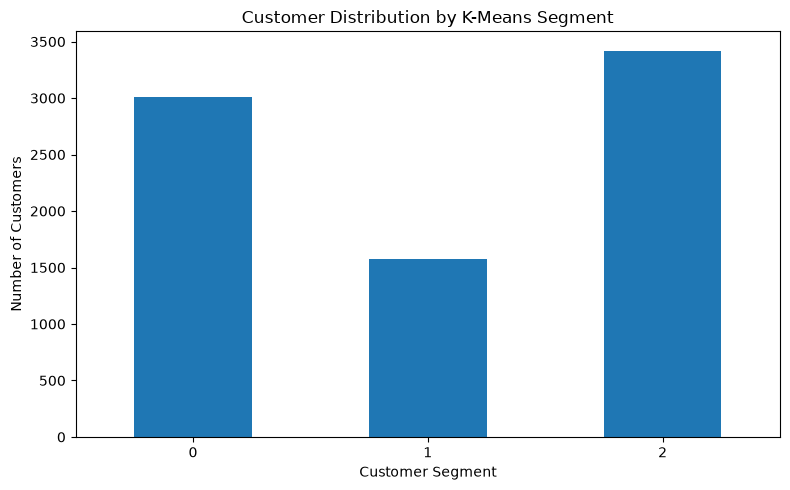

Silhouette Score: -0.033


In [24]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Select analytical features only
features = [
    'total_orders_y',
    'average_order_value',
    'total_spending',
    'ordering_frequency',
    'avg_rating',
    'weekend_orders',
    'late_night_orders'
]

X = customers[features].copy()

# Handle missing values
X = X.fillna(X.median(numeric_only=True))

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply K-Means
# Fit K-Means and assign clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

customers['customer_segment'] = kmeans.fit_predict(X_scaled)

# Display customer IDs and their cluster labels
display(customers[['customer_id', 'customer_segment']].head(10))

customers['customer_segment'].value_counts().sort_index().plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Customer Distribution by K-Means Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

if len(set(non_noise_labels)) >= 2:
    score = silhouette_score(non_noise_data, non_noise_labels)
    print("Silhouette Score:", round(score, 3))
else:
    print("Silhouette Score cannot be calculated: fewer than 2 non-noise clusters.")

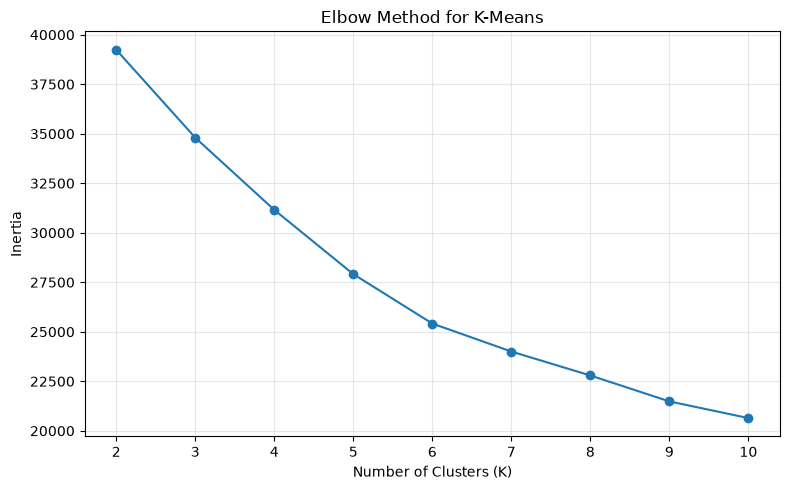

In [25]:
# ==========================================
# 2. ELBOW PLOT
# ==========================================

inertia_values = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia_values.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_values, marker='o')
plt.title('Elbow Method for K-Means')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:
# ==========================================
# 3. TRAIN K-MEANS AND CALCULATE SILHOUETTE
# ==========================================

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

customers['kmeans_segment'] = kmeans.fit_predict(X_scaled)

kmeans_score = silhouette_score(X_scaled, customers['kmeans_segment'])

print("K-Means Silhouette Score:", round(kmeans_score, 3))
print("\nCustomer count per K-Means cluster:")
print(customers['kmeans_segment'].value_counts().sort_index())

K-Means Silhouette Score: 0.178

Customer count per K-Means cluster:
kmeans_segment
0    3009
1    1571
2    3420
Name: count, dtype: int64


In [23]:
# ==========================================
# DBSCAN EVALUATION
# ==========================================

labels = customers['dbscan_segment']
number_of_clusters = len(set(labels)) - (1 if -1 in labels.values else 0)
number_of_noise_points = (labels == -1).sum()

print("Number of clusters:", number_of_clusters)
print("Number of noise points:", number_of_noise_points)

# Silhouette score requires at least 2 clusters,
# and noise points are excluded here for evaluation.
non_noise = labels != -1
non_noise_labels = labels[non_noise]
non_noise_data = X_scaled[non_noise]

if len(set(non_noise_labels)) >= 2:
    score = silhouette_score(non_noise_data, non_noise_labels)
    print("Silhouette Score:", round(score, 3))
else:
    print("Silhouette Score cannot be calculated: fewer than 2 non-noise clusters.")

Number of clusters: 7
Number of noise points: 652
Silhouette Score: -0.033


Variance explained by PC1 and PC2: 63.31 %


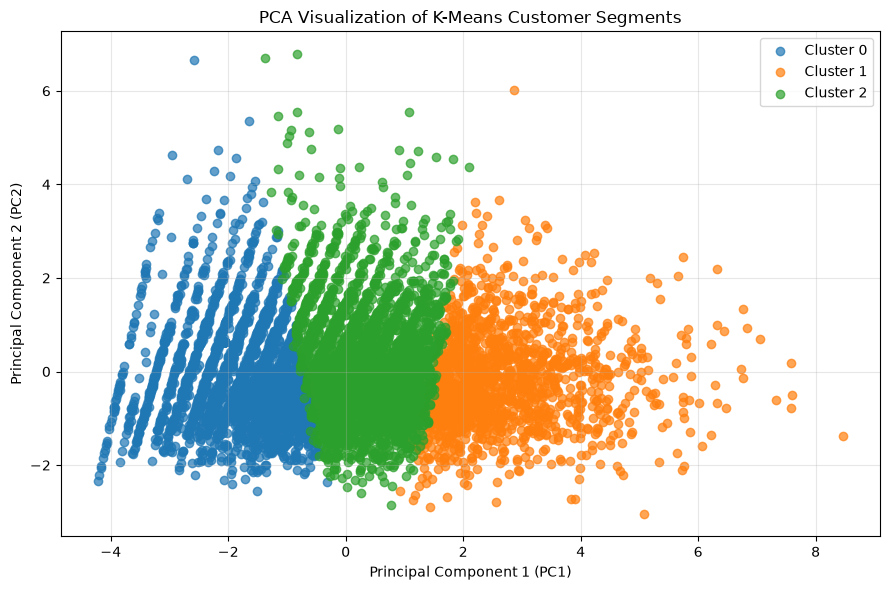

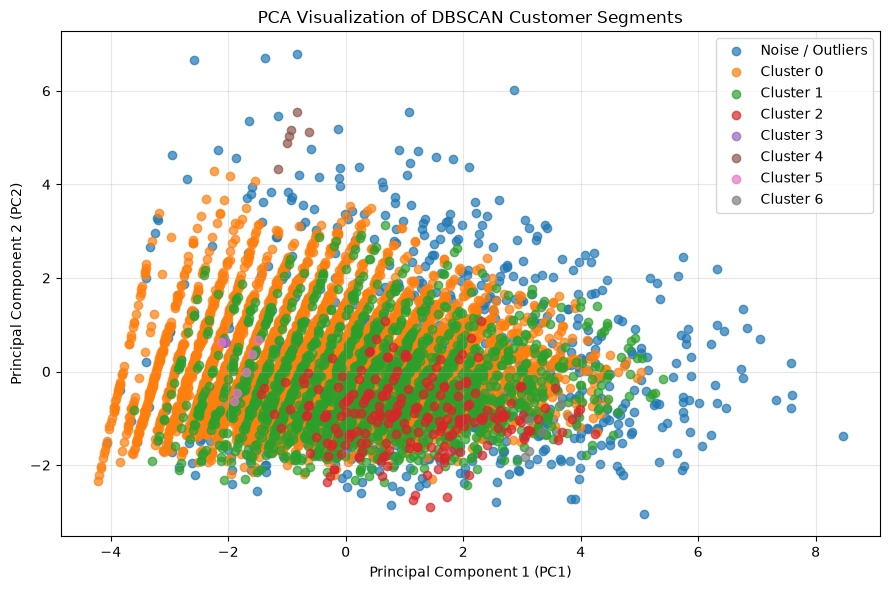

In [27]:
# ==========================================
# 5. PCA VISUALIZATION
# ==========================================

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(
    "Variance explained by PC1 and PC2:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

# K-Means visualization
plt.figure(figsize=(9, 6))

for segment in sorted(customers['kmeans_segment'].unique()):
    mask = customers['kmeans_segment'] == segment
    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=f'Cluster {segment}',
        alpha=0.7
    )

plt.title('PCA Visualization of K-Means Customer Segments')
plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# DBSCAN visualization
plt.figure(figsize=(9, 6))

for segment in sorted(customers['dbscan_segment'].unique()):
    mask = customers['dbscan_segment'] == segment
    label = 'Noise / Outliers' if segment == -1 else f'Cluster {segment}'

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=label,
        alpha=0.7
    )

plt.title('PCA Visualization of DBSCAN Customer Segments')
plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [28]:
# ==========================================
# 6. K-MEANS CLUSTER PROFILES
# ==========================================

profile = customers.groupby('kmeans_segment')[features].mean().round(2)

profile['customer_count'] = (
    customers.groupby('kmeans_segment').size()
)

print(profile)

                total_orders_y  average_order_value  total_spending  \
kmeans_segment                                                        
0                         3.95                51.56          198.41   
1                         9.86                59.39          581.54   
2                         6.64                60.51          391.85   

                ordering_frequency  avg_rating  weekend_orders  \
kmeans_segment                                                   
0                             0.98        4.00            0.97   
1                             2.47        4.01            3.15   
2                             1.66        3.98            1.92   

                late_night_orders  customer_count  
kmeans_segment                                     
0                            0.21            3009  
1                            0.69            1571  
2                            0.34            3420  


In [30]:
# ==========================================
# 7. BUSINESS NAMES FOR K-MEANS CLUSTERS
# ==========================================

profile = customers.groupby('kmeans_segment')[features].mean()

# Convert each cluster's feature values into relative ranks.
# Higher values receive higher ranks.
ranks = profile.rank(pct=True)

def name_cluster(cluster_id):
    row = ranks.loc[cluster_id]

    spending = row.get('total_spending', 0)
    frequency = row.get('ordering_frequency', 0)
    orders = row.get('total_orders', 0)
    late_night = row.get('late_night_orders', 0)
    order_value = row.get('average_order_value', 0)

    if late_night >= 0.67 and spending >= 0.67:
        return 'Late-Night High-Value Customers'
    elif spending >= 0.67 and (frequency >= 0.67 or orders >= 0.67):
        return 'Premium Frequent Diners'
    elif spending <= 0.33 and (frequency <= 0.33 or orders <= 0.33):
        return 'Occasional Budget Customers'
    elif order_value >= 0.67:
        return 'High-Value Order Customers'
    else:
        return 'Regular Dining Customers'

segment_names = {
    cluster_id: name_cluster(cluster_id)
    for cluster_id in profile.index
}

customers['business_segment'] = (
    customers['kmeans_segment'].map(segment_names)
)

print("Business segment names:")
print(segment_names)

print("\nFinal cluster profiles:")
print(
    customers.groupby('business_segment')[features]
    .mean()
    .round(2)
)

print("\nCustomer counts:")
print(customers['business_segment'].value_counts())

Business segment names:
{0: 'Regular Dining Customers', 1: 'Late-Night High-Value Customers', 2: 'High-Value Order Customers'}

Final cluster profiles:
                                 total_orders_y  average_order_value  \
business_segment                                                       
High-Value Order Customers                 6.64                60.51   
Late-Night High-Value Customers            9.86                59.39   
Regular Dining Customers                   3.95                51.56   

                                 total_spending  ordering_frequency  \
business_segment                                                      
High-Value Order Customers               391.85                1.66   
Late-Night High-Value Customers          581.54                2.47   
Regular Dining Customers                 198.41                0.98   

                                 avg_rating  weekend_orders  late_night_orders  
business_segment                                  

In [31]:
# ==========================================
# 8. SAVE FINAL OUTPUTS
# ==========================================

customers.to_csv('/home/ninelaps/uber-ml/data/csv/customer_segments_final.csv', index=False)
profile.to_csv('/home/ninelaps/uber-ml/data/csv/kmeans_cluster_profiles.csv')

print("Saved customer_segments_final.csv")
print("Saved kmeans_cluster_profiles.csv")

Saved customer_segments_final.csv
Saved kmeans_cluster_profiles.csv
